# PlantSeg Stage 1 — Session 3: Aggregator

Loads all 8 `result_*.pkl` files collected from Sessions 1 & 2, then runs the full aggregation pipeline:
- **Sec 10** Load results & build metrics / deployment tables
- **Sec 11** Dataset presentation figures (Fig 1–2)
- **Sec 12** Preprocessing & augmentation figures (Fig 3)
- **Sec 13** Top-3 softmax-average ensemble
- **Sec 14** Rendered model comparison table
- **Sec 15** Combined aggregate figures (training curves, ROC, frontier, per-class heatmap)
- **Sec 16** Train / val / test accuracy overfitting check
- **Sec 17** Cross-split near-duplicate leakage audit
- **Sec 18** McNemar test, bootstrap CIs & fruit sub-analysis

> **Setup:** Upload all 8 `.pkl` files from Sessions 1 & 2 as a Kaggle dataset  
> (e.g. `/kaggle/input/s1-results/`). The aggregator cell auto-detects the path.

> **Kaggle note:** Internet **ON** for `timm`. The aggregator does NOT retrain any model.

## Section 1 — Install Dependencies & Imports

Installs `timm`, `imagehash`, `statsmodels`, and `grad-cam`, then imports all required libraries and sets a global random seed for reproducibility.

In [1]:
!pip install -q timm imagehash statsmodels grad-cam
import os, json, math, time, random, warnings, pickle
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision; from torchvision import transforms
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("Device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 63.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 99.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inco

## Section 2 — Global Configuration

Set `DATA_ROOT` to the PlantSeg dataset mount and `OUTDIR` to the output directory.
All 8 models share the same hyperparameters defined here. Change `MODELS_TO_TRAIN`
to run a subset, or set `QUICK_SMOKE = True` for a fast sanity-check (1 epoch,
8 images per class).


In [2]:
# ============ CONFIG ============
# Edit DATA_ROOT to point at your PlantSeg dataset mount
DATA_ROOT = Path("/kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg")
if not (DATA_ROOT/"Metadata.csv").exists():
    for cand in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (cand/"Metadata.csv").exists(): DATA_ROOT=cand; break
assert (DATA_ROOT/"Metadata.csv").exists(), f"Metadata.csv not found under {DATA_ROOT} — edit DATA_ROOT."

OUTDIR = Path("/kaggle/working/s1_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# List of all 8 models to train sequentially.
# Remove any name from this list to skip it.
MODELS_TO_TRAIN = [
    "MobileNetV3Large",  # Trainer 1/8
    "EfficientNetB0",    # Trainer 2/8
    "ResNet50",          # Trainer 3/8
    "EfficientNetV2S",   # Trainer 4/8
    "ConvNeXtV2Tiny",    # Trainer 5/8
    "ViTBase16",         # Trainer 6/8 — transformer
    "SwinTiny",          # Trainer 7/8 — transformer
    "GatedFusionLight",  # Trainer 8/8 — dual-branch fusion
]

SCOPE = "full"   # "full" = all plants | "fruit" = fruit hosts only
FRUIT_HOSTS = {"Apple","Citrus","Grape","Banana","Peach","Blueberry",
               "Plum","Cherry","Raspberry","Strawberry"}

NUM_EPOCHS      = 40
PATIENCE        = 8
LR              = 3e-4
WEIGHT_DECAY    = 1e-4
USE_PRETRAINED  = True
USE_CLASS_WEIGHTS = True
LABEL_SMOOTHING = 0.05
IMG_SIZE_CNN    = 384   # lower to 320 or 256 if OOM
USE_RANDAUG     = True
USE_TTA         = True
QUICK_SMOKE     = False  # True → 1 epoch, 8 imgs/class (fast sanity check)

print("DATA_ROOT:", DATA_ROOT)
print("Models to train:", MODELS_TO_TRAIN)


DATA_ROOT: /kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg
Models to train: ['MobileNetV3Large', 'EfficientNetB0', 'ResNet50', 'EfficientNetV2S', 'ConvNeXtV2Tiny', 'ViTBase16', 'SwinTiny', 'GatedFusionLight']


## Section 3 — Dataset Index & Class Weights

Reads `Metadata.csv`, resolves image paths, filters to `SCOPE`, and computes
inverse-frequency class weights used in the cross-entropy loss.
Prints split sizes and number of disease classes.


In [3]:
# ============ DATA INDEX ============
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
meta["label"] = meta["Disease"]; meta["plant"] = meta["Plant"]
if SCOPE == "fruit":
    meta = meta[meta["plant"].isin(FRUIT_HOSTS)].reset_index(drop=True)
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label2idx = {c: i for i, c in enumerate(CLASS_NAMES)}

train_df = meta[meta.split=="train"].reset_index(drop=True)
val_df   = meta[meta.split=="val"].reset_index(drop=True)
test_df  = meta[meta.split=="test"].reset_index(drop=True)

if QUICK_SMOKE:
    train_df = train_df.groupby("label",group_keys=False).head(8).reset_index(drop=True)
    val_df   = val_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    test_df  = test_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    NUM_EPOCHS = 1

counts = train_df["label"].map(label2idx).value_counts().reindex(range(NUM_CLASSES)).fillna(0)
inv = np.where(counts.values > 0, 1.0/counts.values, 0.0)
cw  = inv / inv[inv>0].mean()
class_weights = torch.tensor(cw, dtype=torch.float32, device=device)

print(f"classes={NUM_CLASSES}  train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")


classes=115  train=5367  val=846  test=1561


## Re-run: Transforms & Dataset Class

*(Required for the dataset presentation and preprocessing figure cells — no training performed)*

In [4]:
# ============ TRANSFORMS / DATASET ============
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

def make_transforms(sz):
    ops = [transforms.RandomResizedCrop(sz, scale=(0.7,1.0)),
           transforms.RandomHorizontalFlip(),
           transforms.RandomVerticalFlip(p=0.2)]
    if USE_RANDAUG:
        ops += [transforms.RandAugment(num_ops=2, magnitude=9)]
    else:
        ops += [transforms.RandomRotation(15),
                transforms.ColorJitter(0.2, 0.2, 0.2, 0.05)]
    ops += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if USE_RANDAUG:
        ops += [transforms.RandomErasing(p=0.25)]
    ev = transforms.Compose([transforms.Resize((sz,sz)),
                             transforms.ToTensor(),
                             transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops), ev

class DS(Dataset):
    def __init__(self, d, t):
        self.df = d.reset_index(drop=True); self.t = t
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.t(Image.open(r.filepath).convert("RGB")), label2idx[r.label]


---
## Section 10 — Aggregator: Load Results & Build Metrics Table

Loads all `result_*.pkl` files from `OUTDIR` (or a separate `RESULTS_IN` path if
you collected results across Kaggle sessions) into `all_results`. Builds a unified
`metrics_df` DataFrame sorted by macro-F1, and a `deployment_df` with parameter
counts and latency figures.


In [5]:
# ============ AGGREGATOR — LOAD RESULTS ============
import json as _json
from statsmodels.stats.contingency_tables import mcnemar

# If you ran trainers in separate sessions, set RESULTS_IN to the folder with .pkl files.
# Otherwise it defaults to the same OUTDIR used above.
RESULTS_IN = OUTDIR
if not list(RESULTS_IN.glob("result_*.pkl")):
    for c in [Path("/kaggle/input/datasets/mdmarufbangabashi/s1-resultss"), Path("s1_results"), Path(".")]:
        if list(c.glob("result_*.pkl")): RESULTS_IN=c; break

AGG_OUT = Path("/kaggle/working/s1_aggregate")
AGG_FIG = AGG_OUT/"figures"; AGG_RES = AGG_OUT/"results"
AGG_FIG.mkdir(parents=True, exist_ok=True); AGG_RES.mkdir(parents=True, exist_ok=True)

ENSEMBLE_TOPK = 3

all_results={}; metrics_table={}; cms_agg={}; deploy_agg={}
for p in sorted(RESULTS_IN.glob("result_*.pkl")):
    r = pickle.load(open(p,"rb")); n = r["model_name"]
    all_results[n] = {"y_true": r["y_true"], "y_pred": r["y_pred"], "y_prob": r["y_prob"],
                      "history": r["history"], "img_size": r["img_size"]}
    metrics_table[n]=r["metrics"]; cms_agg[n]=r["cm"]; deploy_agg[n]=r["deployment"]

deployment_df = pd.DataFrame(deploy_agg).T
metrics_df    = pd.DataFrame(metrics_table).T.join(deployment_df).sort_values("f1_macro", ascending=False)
print(f"Loaded {len(all_results)} models:", list(all_results))
print(metrics_df.round(4))


Loaded 8 models: ['ConvNeXtV2Tiny', 'EfficientNetB0', 'EfficientNetV2S', 'GatedFusionLight', 'MobileNetV3Large', 'ResNet50', 'SwinTiny', 'ViTBase16']
                  accuracy  balanced_accuracy  f1_macro  f1_weighted  \
ConvNeXtV2Tiny      0.7841             0.7370    0.7246       0.7852   
EfficientNetV2S     0.7611             0.7152    0.7026       0.7588   
ViTBase16           0.7611             0.7061    0.7005       0.7591   
SwinTiny            0.7585             0.7032    0.6888       0.7570   
ResNet50            0.7444             0.6916    0.6765       0.7413   
MobileNetV3Large    0.7335             0.6793    0.6701       0.7301   
EfficientNetB0      0.7245             0.6619    0.6533       0.7256   
GatedFusionLight    0.6912             0.6269    0.6214       0.6875   

                  precision_macro  recall_macro     mcc  roc_auc_macro  \
ConvNeXtV2Tiny             0.7412        0.7305  0.7812         0.9689   
EfficientNetV2S            0.7198        0.7090  0.75

## Section 11 — Dataset Presentation Figures

Generates Fig 1–2:
- Class distribution bar chart and official split sizes  
- Sample in-the-wild images per host plant  
- Composition bar chart (images + disease count per host)


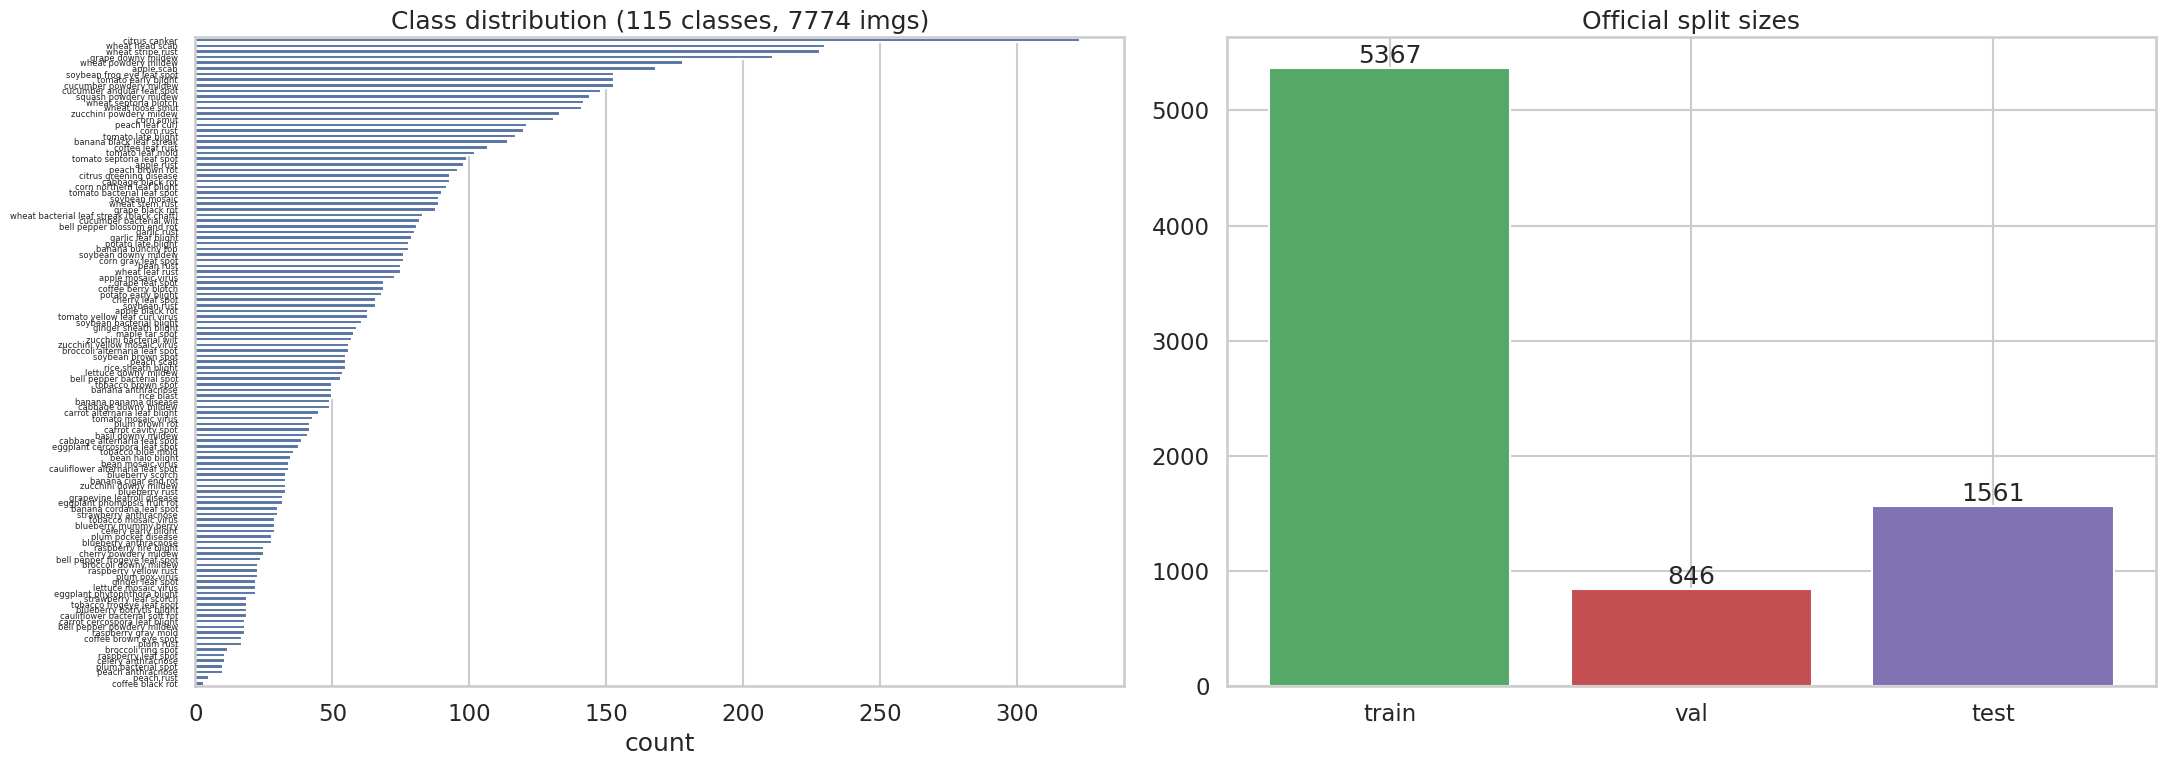

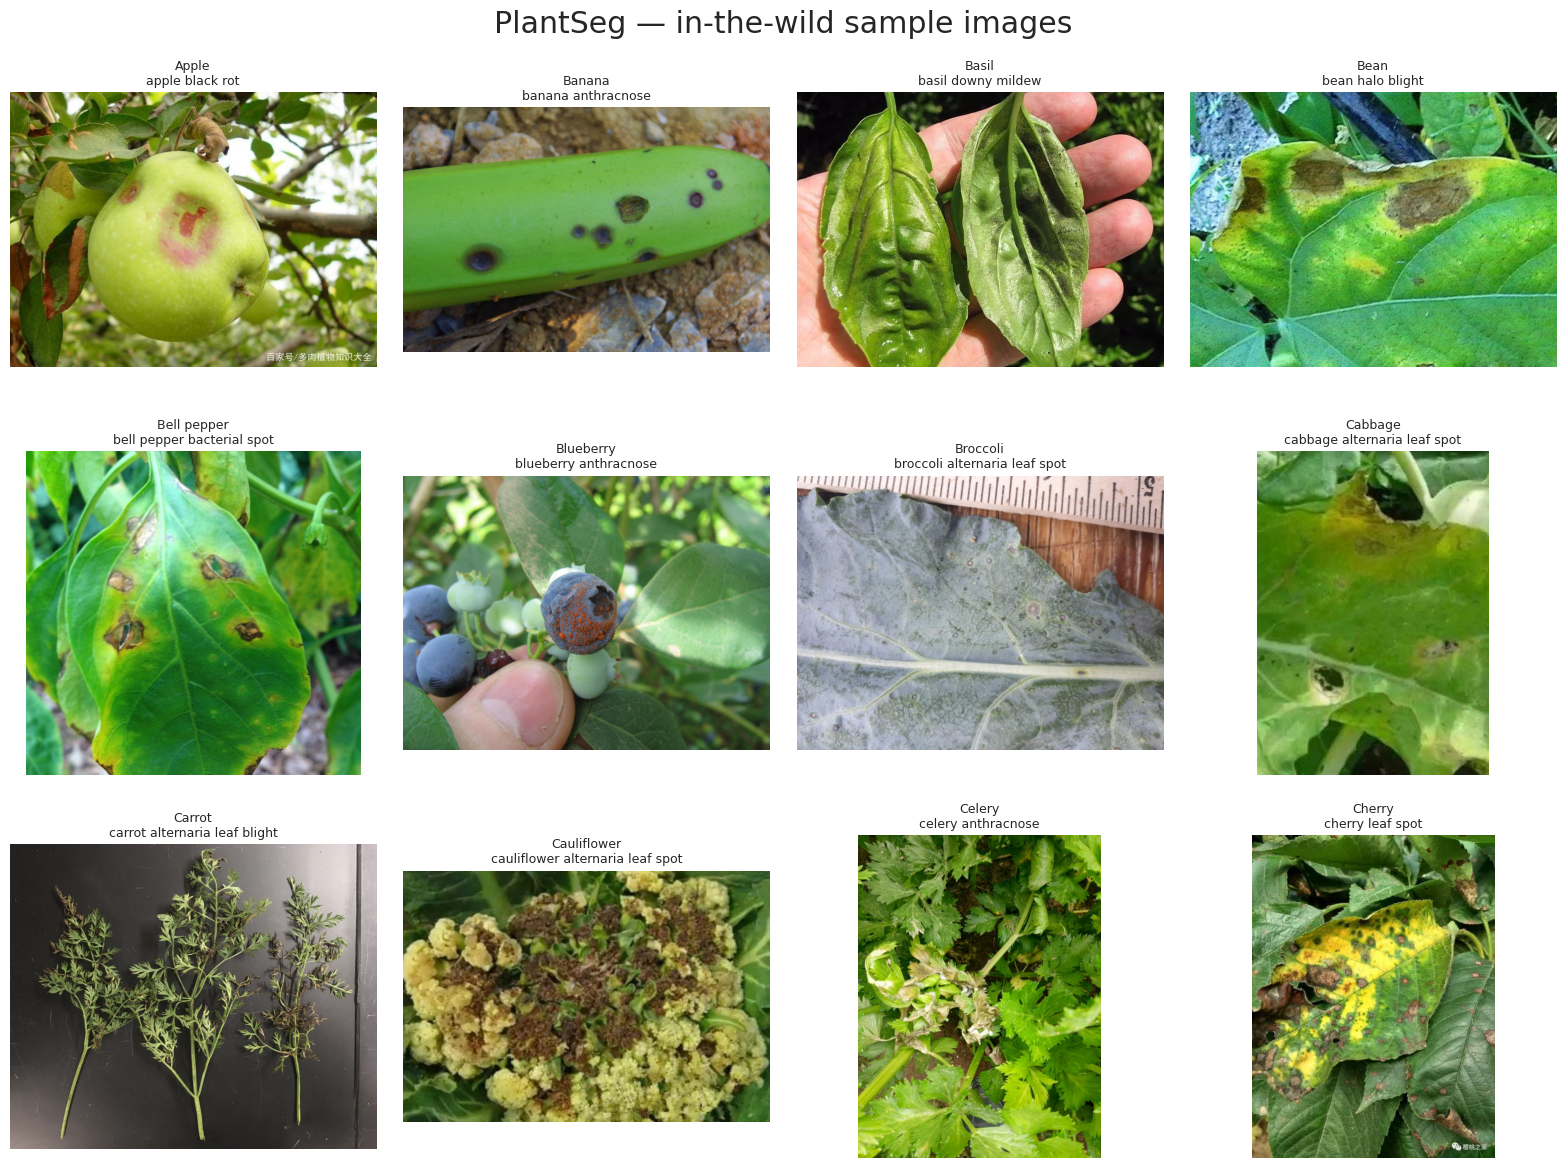

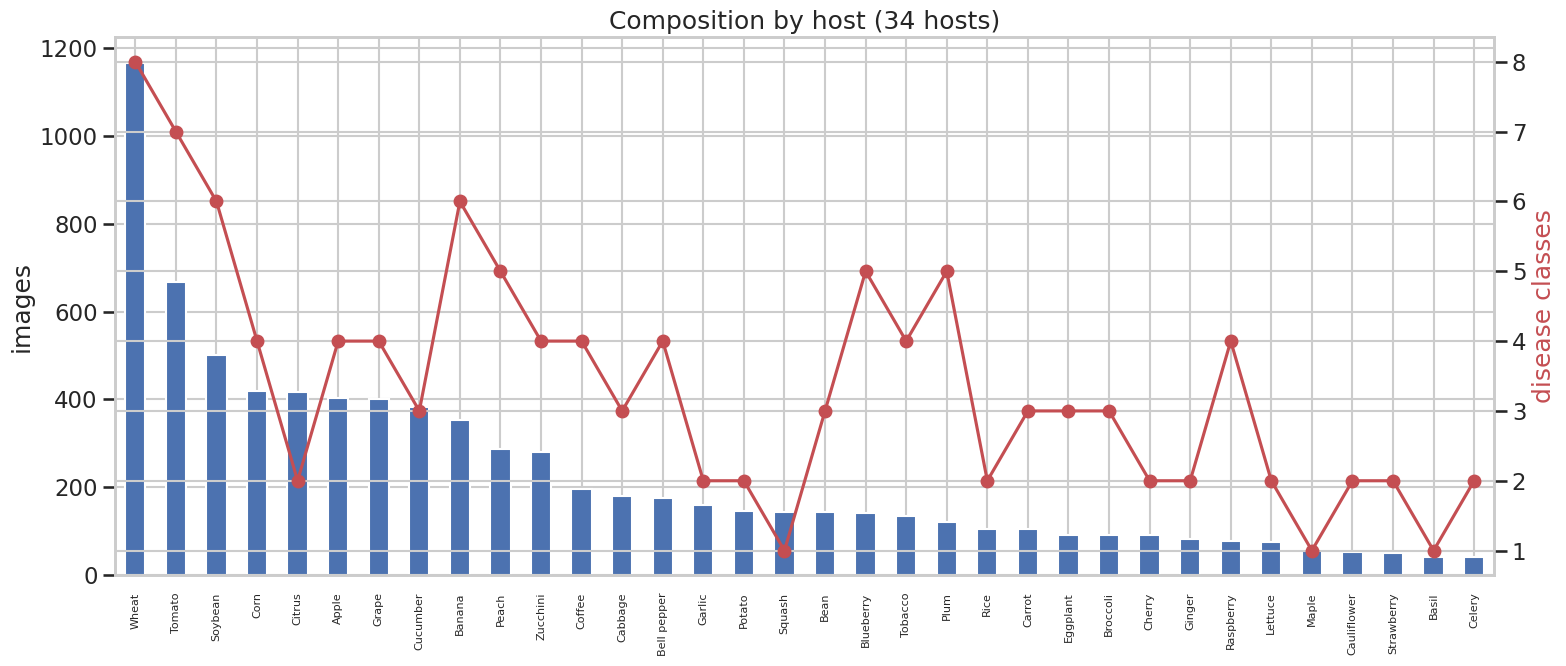

In [6]:
# ============ DATASET-PRESENTATION FIGURES (Fig 1-2) ============
fig, ax = plt.subplots(1, 2, figsize=(22,8))
order = meta["label"].value_counts().index
sns.countplot(data=meta, y="label", order=order, ax=ax[0], color="#4C72B0")
ax[0].set_title(f"Class distribution ({NUM_CLASSES} classes, {len(meta)} imgs)")
ax[0].set_ylabel(""); ax[0].tick_params(axis="y", labelsize=6)
sc = meta.groupby("split").size().reindex(["train","val","test"])
ax[1].bar(sc.index, sc.values, color=["#55A868","#C44E52","#8172B3"])
for i,v in enumerate(sc.values): ax[1].text(i, v, str(v), ha="center", va="bottom")
ax[1].set_title("Official split sizes")
plt.tight_layout(); plt.savefig(AGG_FIG/"fig01_class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()
sc.to_csv(AGG_RES/"table_splits.csv")

hosts = sorted(meta["plant"].unique())[:12]; n = len(hosts); cols=4; rows=math.ceil(n/cols)
fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows))
for a,h in zip(axes.flatten(), hosts):
    r = meta[meta.plant==h].iloc[0]
    a.imshow(Image.open(r.filepath).convert("RGB")); a.set_title(f"{h}\n{r.label}", fontsize=9); a.axis("off")
for a in axes.flatten()[n:]: a.axis("off")
plt.suptitle("PlantSeg — in-the-wild sample images"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig02_samples.png", dpi=150, bbox_inches="tight"); plt.show()

ht = meta.groupby("plant").agg(images=("label","size"), diseases=("label","nunique")).sort_values("images",ascending=False)
ht.to_csv(AGG_RES/"table_per_host.csv")
fig, ax = plt.subplots(figsize=(16,7)); ht["images"].plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("images"); ax.set_xlabel("")
a2 = ax.twinx(); a2.plot(range(len(ht)), ht["diseases"].values, "o-", color="#C44E52")
a2.set_ylabel("disease classes", color="#C44E52")
ax.set_title(f"Composition by host ({meta.plant.nunique()} hosts)")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
plt.tight_layout(); plt.savefig(AGG_FIG/"fig02b_per_host.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 12 — Preprocessing & Augmentation Figures

Visualises the preprocessing pipeline (original → resized → normalised) and shows
each augmentation operation applied independently to the same sample image (Fig 3).


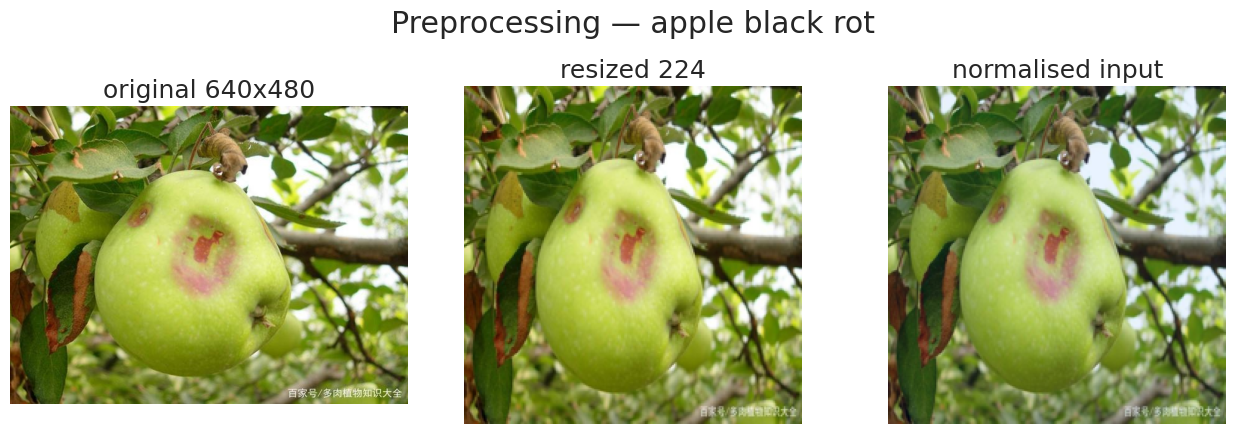

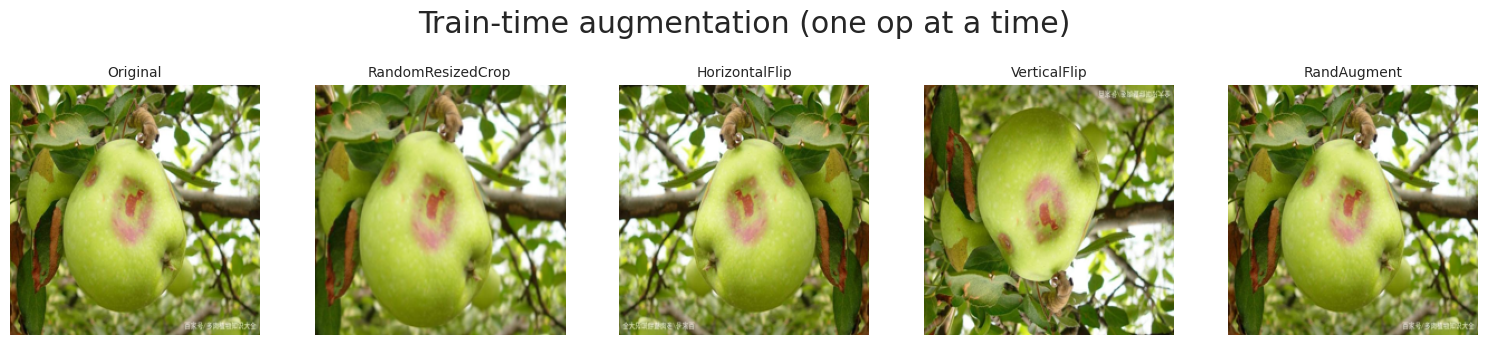

In [7]:
# ============ PREPROCESSING + AUGMENTATION FIGURES (Fig 3) ============
r0 = meta[meta.split=="train"].iloc[0]
orig = Image.open(r0.filepath).convert("RGB"); resized = orig.resize((224,224))
nt = transforms.Normalize(MEAN,STD)(transforms.ToTensor()(resized)).permute(1,2,0).numpy()
nt = (nt-nt.min())/(np.ptp(nt)+1e-8)
fig, ax = plt.subplots(1, 3, figsize=(13,4.5))
ax[0].imshow(orig); ax[0].set_title(f"original {orig.size[0]}x{orig.size[1]}")
ax[1].imshow(resized); ax[1].set_title("resized 224")
ax[2].imshow(nt); ax[2].set_title("normalised input")
for a in ax: a.axis("off")
plt.suptitle(f"Preprocessing — {r0.label}"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig03a_preprocessing.png", dpi=200, bbox_inches="tight"); plt.show()

aug = {"Original": None,
       "RandomResizedCrop": transforms.RandomResizedCrop(224, scale=(0.7,1.0)),
       "HorizontalFlip": transforms.RandomHorizontalFlip(p=1),
       "VerticalFlip": transforms.RandomVerticalFlip(p=1),
       "RandAugment": transforms.RandAugment(num_ops=2, magnitude=9)}
base = orig.resize((224,224))
fig, axes = plt.subplots(1, len(aug), figsize=(3.1*len(aug), 3.6))
for a,(nm,op) in zip(axes, aug.items()):
    a.imshow(base if op is None else op(base)); a.set_title(nm, fontsize=10); a.axis("off")
plt.suptitle("Train-time augmentation (one op at a time)"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig03b_augmentation.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 13 — Top-K Softmax-Average Ensemble

Builds an ensemble from the top-`ENSEMBLE_TOPK` models (by macro-F1) using
softmax-probability averaging. Adds the ensemble as a new row in `metrics_df`
and saves the updated comparison table to CSV.


In [8]:
# ============ TOP-K ENSEMBLE ============
topk = metrics_df.index[:ENSEMBLE_TOPK].tolist()
y_true = all_results[topk[0]]["y_true"]
ens_prob = np.mean([all_results[n]["y_prob"] for n in topk], axis=0)
ens_pred = ens_prob.argmax(1)

def cmet(y, yp, ypb, n):
    cm = confusion_matrix(y, yp, labels=range(n))
    present = [c for c in range(n) if (y==c).sum()>0]; a=[]
    for c in present:
        try: a.append(roc_auc_score((y==c).astype(int), ypb[:,c]))
        except Exception: pass
    return {"accuracy": accuracy_score(y,yp), "balanced_accuracy": balanced_accuracy_score(y,yp),
            "f1_macro": f1_score(y,yp,average="macro"), "f1_weighted": f1_score(y,yp,average="weighted"),
            "precision_macro": precision_score(y,yp,average="macro",zero_division=0),
            "recall_macro": recall_score(y,yp,average="macro",zero_division=0),
            "mcc": matthews_corrcoef(y,yp),
            "roc_auc_macro": float(np.mean(a)) if a else float("nan")}, cm

em, ecm = cmet(y_true, ens_pred, ens_prob, NUM_CLASSES)
en = f"Ensemble_top{ENSEMBLE_TOPK}"
all_results[en] = {"y_true": y_true, "y_pred": ens_pred, "y_prob": ens_prob, "history": None, "img_size": None}
cms_agg[en] = ecm
erow = {**em,
        "params_M": float(metrics_df.loc[topk,"params_M"].sum()),
        "checkpoint_size_MB": float(metrics_df.loc[topk,"checkpoint_size_MB"].sum()),
        "latency_cpu_ms": float(metrics_df.loc[topk,"latency_cpu_ms"].sum()),
        "latency_gpu_ms": float(metrics_df.loc[topk,"latency_gpu_ms"].sum())}
metrics_df = pd.concat([metrics_df, pd.DataFrame([erow], index=[en])]).sort_values("f1_macro", ascending=False)
metrics_df.to_csv(AGG_RES/"model_comparison_metrics.csv")
print(f"{en} ({'+'.join(topk)}): acc={em['accuracy']:.4f} f1={em['f1_macro']:.4f} mcc={em['mcc']:.4f}")
print(metrics_df.round(4))
best_model_name = [m for m in metrics_df.index if m != en][0]


Ensemble_top3 (ConvNeXtV2Tiny+EfficientNetV2S+ViTBase16): acc=0.7963 f1=0.7369 mcc=0.7935
                  accuracy  balanced_accuracy  f1_macro  f1_weighted  \
Ensemble_top3       0.7963             0.7452    0.7369       0.7928   
ConvNeXtV2Tiny      0.7841             0.7370    0.7246       0.7852   
EfficientNetV2S     0.7611             0.7152    0.7026       0.7588   
ViTBase16           0.7611             0.7061    0.7005       0.7591   
SwinTiny            0.7585             0.7032    0.6888       0.7570   
ResNet50            0.7444             0.6916    0.6765       0.7413   
MobileNetV3Large    0.7335             0.6793    0.6701       0.7301   
EfficientNetB0      0.7245             0.6619    0.6533       0.7256   
GatedFusionLight    0.6912             0.6269    0.6214       0.6875   

                  precision_macro  recall_macro     mcc  roc_auc_macro  \
Ensemble_top3              0.7623        0.7387  0.7935         0.9771   
ConvNeXtV2Tiny             0.7412        

## Section 14 — Rendered Comparison Table

Renders the model comparison table as a Matplotlib figure (saved as PNG) for
easy inclusion in reports. Columns: accuracy, balanced accuracy, macro-F1, MCC,
ROC-AUC, parameter count, and CPU latency.


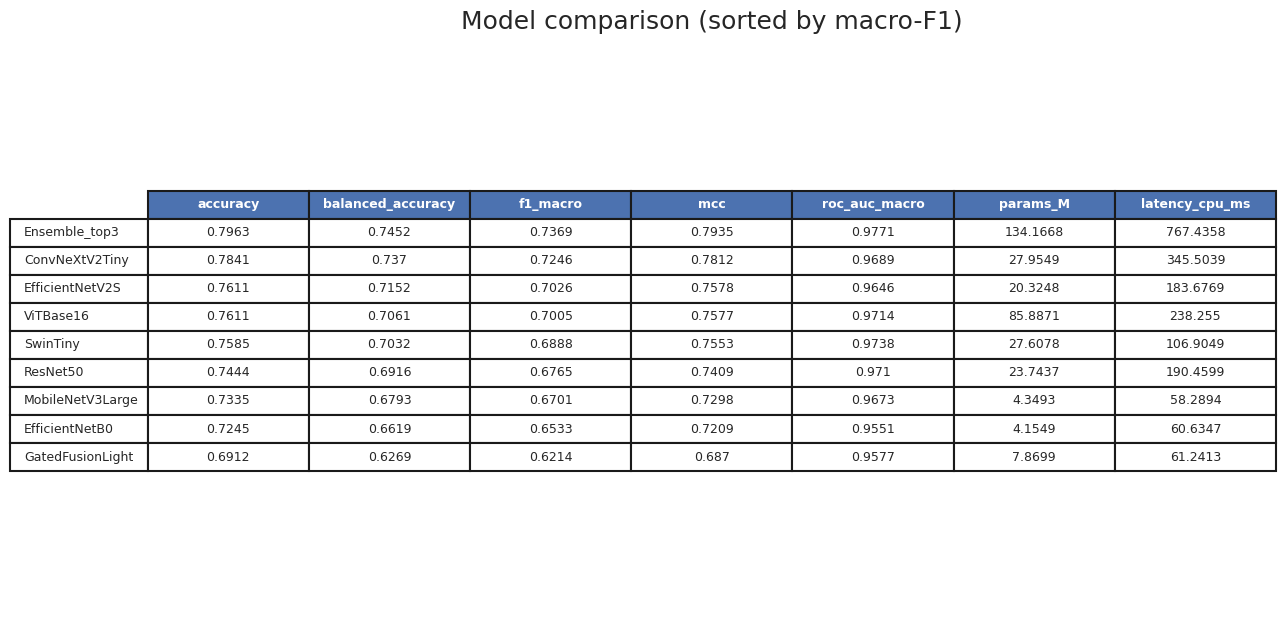

In [9]:
# ============ RENDERED COMPARISON TABLE ============
cols = ["accuracy","balanced_accuracy","f1_macro","mcc","roc_auc_macro","params_M","latency_cpu_ms"]
tbl = metrics_df[cols].round(4)
fig, ax = plt.subplots(figsize=(2+1.6*len(cols), 0.6*len(tbl)+1.2)); ax.axis("off")
t = ax.table(cellText=tbl.values, rowLabels=tbl.index, colLabels=cols, loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.5)
for j in range(len(cols)):
    t[0,j].set_facecolor("#4C72B0"); t[0,j].set_text_props(color="w", weight="bold")
plt.title("Model comparison (sorted by macro-F1)", pad=12); plt.tight_layout()
plt.savefig(AGG_FIG/"table_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 15 — Combined Aggregate Figures

Produces four cross-model visualisations:
1. **Training curves** (loss + val accuracy) for all trained models in a grid  
2. **Headline metrics bar chart** (macro-F1, balanced accuracy, MCC, accuracy)  
3. **Micro-average ROC curves** for all models on one axes  
4. **Accuracy–efficiency frontier** (macro-F1 vs CPU latency, bubble size = params)  
5. **Per-class recall heatmap** across all models


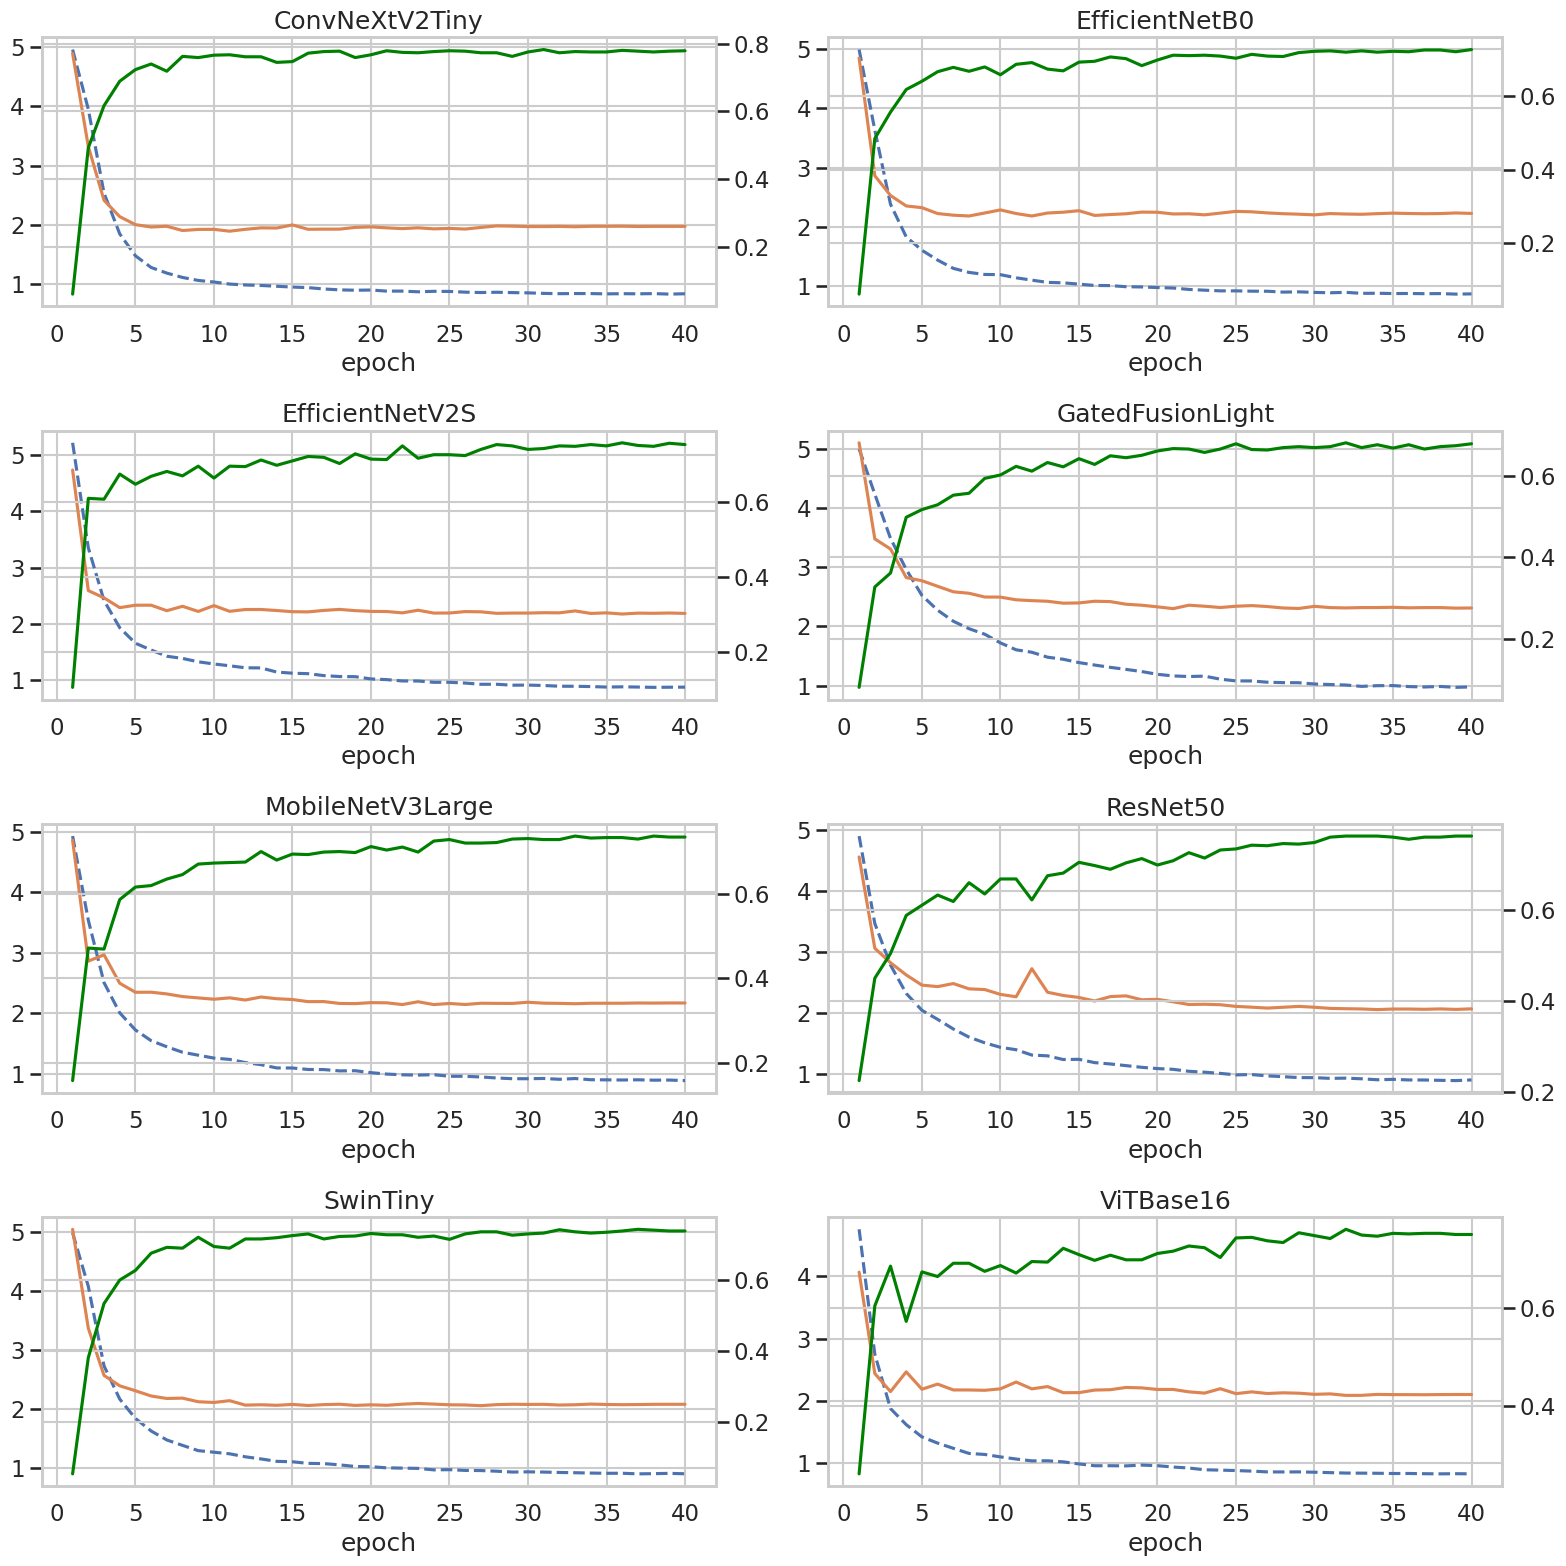

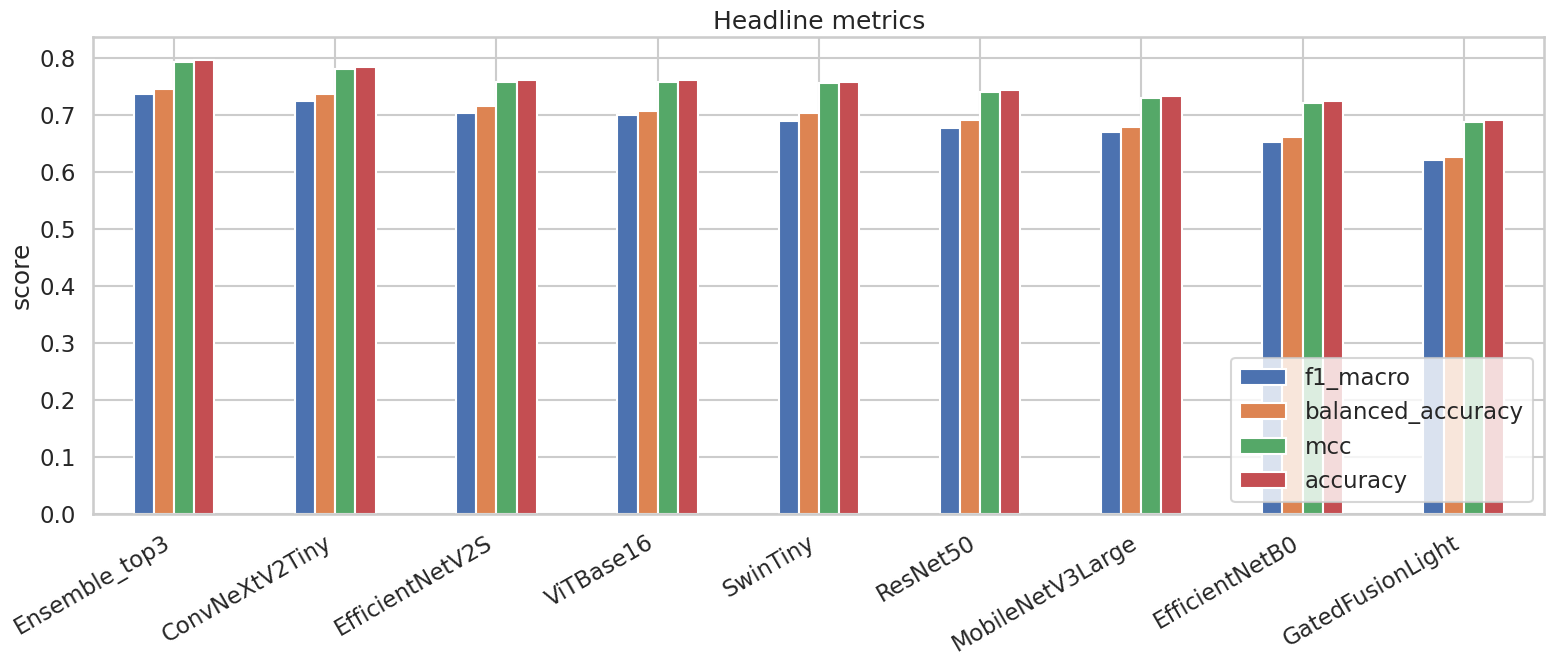

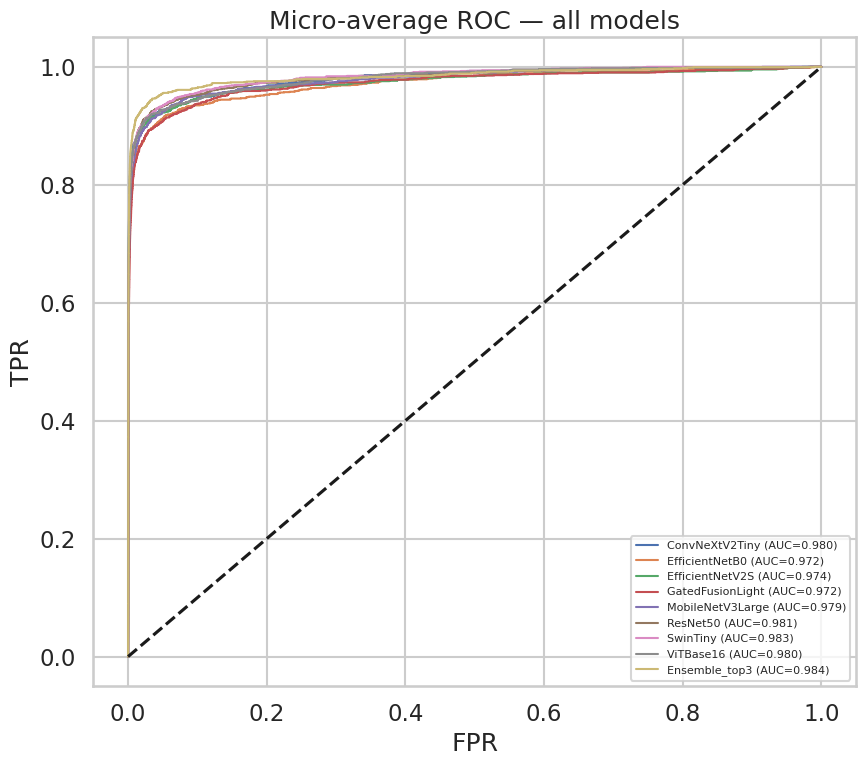

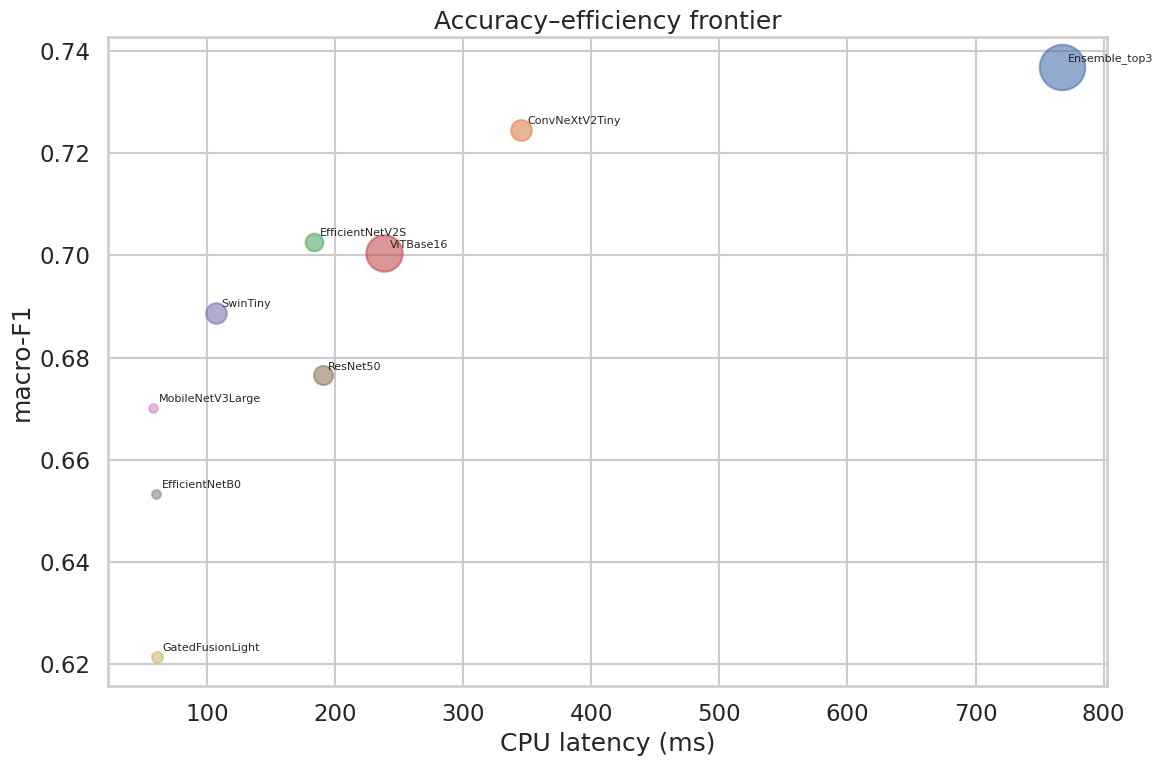

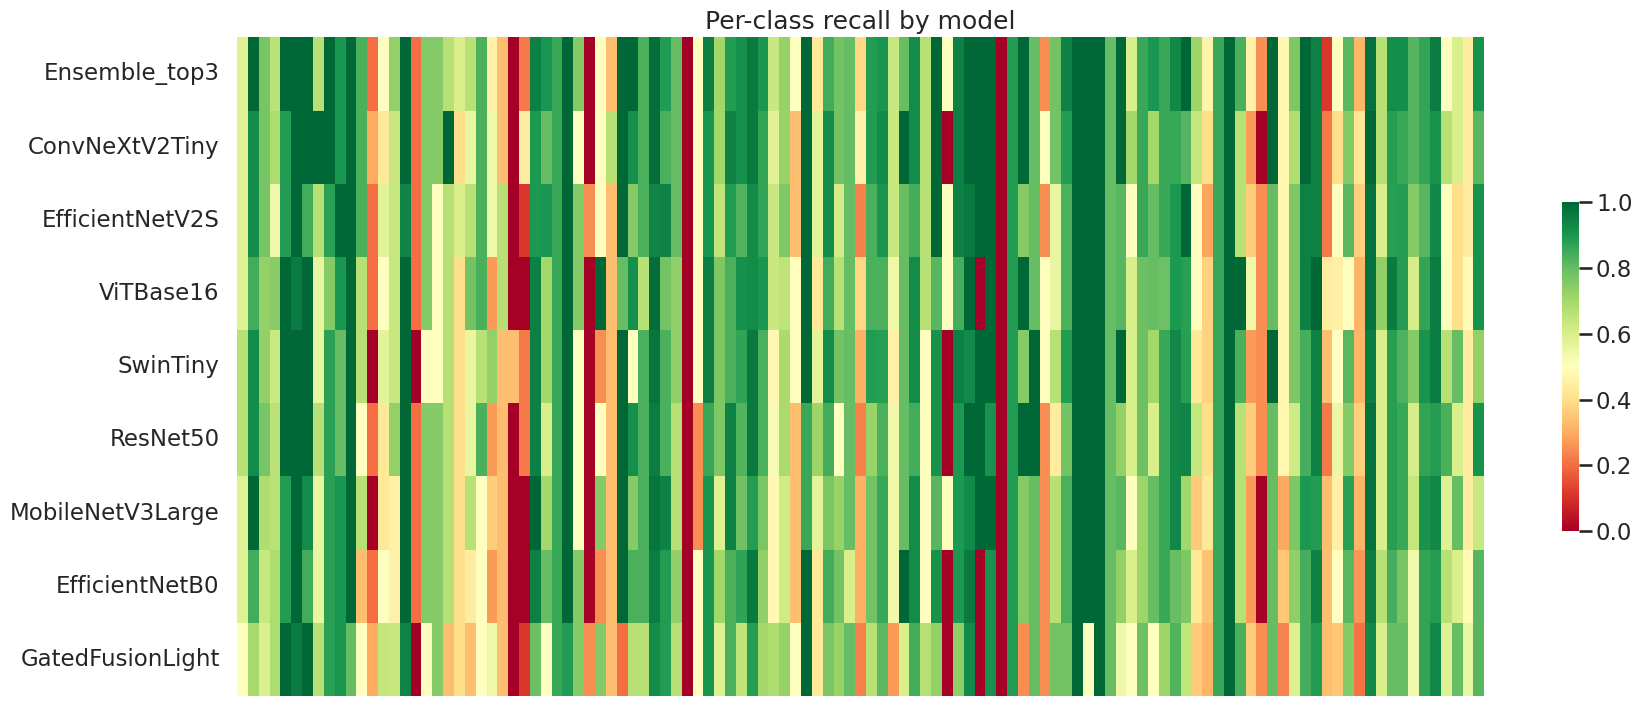

In [10]:
# ============ COMBINED AGGREGATE FIGURES ============
trained = [(n,r) for n,r in all_results.items() if r["history"] is not None]
n = len(trained); cols=2; rows=math.ceil(n/cols)
fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows)); axes = np.array(axes).flatten()
for ax,(nm,r) in zip(axes, trained):
    h=r["history"]; ep=range(1,len(h["train_loss"])+1)
    ax.plot(ep, h["train_loss"], "--", label="train loss"); ax.plot(ep, h["val_loss"], label="val loss")
    a2=ax.twinx(); a2.plot(ep, h["val_acc"], color="green"); ax.set_title(nm); ax.set_xlabel("epoch")
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig(AGG_FIG/"fig_training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# Headline metrics bar chart
ax = metrics_df[["f1_macro","balanced_accuracy","mcc","accuracy"]].plot(kind="bar", figsize=(16,7))
ax.set_title("Headline metrics"); ax.set_ylabel("score"); ax.legend(loc="lower right")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

# ROC — all models (micro)
plt.figure(figsize=(9,8))
for nm,r in all_results.items():
    yoh = np.eye(NUM_CLASSES)[r["y_true"]]; fpr,tpr,_ = roc_curve(yoh.ravel(), r["y_prob"].ravel())
    plt.plot(fpr, tpr, lw=1.5, label=f"{nm} (AUC={auc(fpr,tpr):.3f})")
plt.plot([0,1],[0,1],"k--"); plt.legend(fontsize=8, loc="lower right")
plt.title("Micro-average ROC — all models"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.tight_layout(); plt.savefig(AGG_FIG/"fig_roc_all.png", dpi=200, bbox_inches="tight"); plt.show()

# Accuracy-efficiency frontier
fig, ax = plt.subplots(figsize=(12,8))
for nm in metrics_df.index:
    x=metrics_df.loc[nm,"latency_cpu_ms"]; y=metrics_df.loc[nm,"f1_macro"]; s=metrics_df.loc[nm,"params_M"]
    ax.scatter(x, y, s=max(40,s*8), alpha=0.6)
    ax.annotate(nm, (x,y), fontsize=8, xytext=(4,4), textcoords="offset points")
ax.set_xlabel("CPU latency (ms)"); ax.set_ylabel("macro-F1"); ax.set_title("Accuracy–efficiency frontier")
plt.tight_layout(); plt.savefig(AGG_FIG/"fig_frontier.png", dpi=200, bbox_inches="tight"); plt.show()

# Per-class accuracy heatmap
pc  = {nm: (cms_agg[nm].astype(float).diagonal()/cms_agg[nm].astype(float).sum(1).clip(min=1))
       for nm in metrics_df.index}
pcd = pd.DataFrame(pc, index=CLASS_NAMES).T; pcd.to_csv(AGG_RES/"per_class_accuracy.csv")
plt.figure(figsize=(max(12,NUM_CLASSES*0.16), 0.6*len(metrics_df)+2))
sns.heatmap(pcd, cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"shrink":0.5},
            xticklabels=(NUM_CLASSES<=45))
plt.title("Per-class recall by model"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig_per_class.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 16 — Train / Val / Test Accuracy (Overfitting Check)

Compares final train, validation, and test accuracy for each model side-by-side.
A large `train_acc − test_acc` gap indicates overfitting. Results are saved to
`train_val_test_accuracy.csv`.


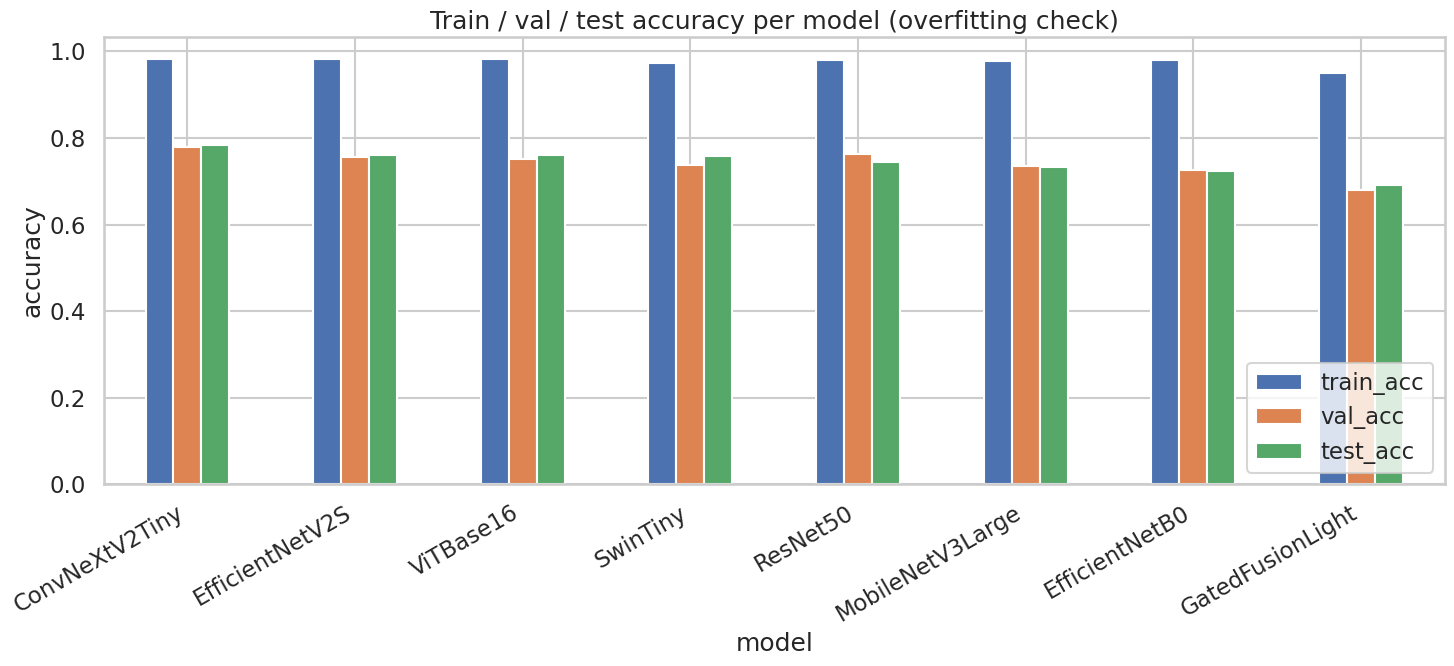

                  train_acc  val_acc  test_acc  gap_train_minus_test
model                                                               
ConvNeXtV2Tiny       0.9832   0.7790    0.7841                0.1991
EfficientNetV2S      0.9815   0.7553    0.7611                0.2205
ViTBase16            0.9826   0.7518    0.7611                0.2216
SwinTiny             0.9733   0.7376    0.7585                0.2148
ResNet50             0.9789   0.7636    0.7444                0.2345
MobileNetV3Large     0.9768   0.7340    0.7335                0.2433
EfficientNetB0       0.9808   0.7270    0.7245                0.2562
GatedFusionLight     0.9507   0.6797    0.6912                0.2595


In [11]:
# ============ TRAIN/VAL/TEST ACCURACY — OVERFITTING CHECK ============
rows = []
for nm,r in all_results.items():
    if r["history"] is None: continue
    rows.append({"model": nm,
                 "train_acc": r["history"]["train_acc"][-1],
                 "val_acc":   r["history"]["val_acc"][-1],
                 "test_acc":  metrics_df.loc[nm,"accuracy"]})
g = pd.DataFrame(rows).set_index("model")
g = g.loc[[m for m in metrics_df.index if m in g.index]]
g["gap_train_minus_test"] = (g["train_acc"]-g["test_acc"]).round(4)
g.to_csv(AGG_RES/"train_val_test_accuracy.csv")
ax = g[["train_acc","val_acc","test_acc"]].plot(kind="bar", figsize=(15,7))
ax.set_title("Train / val / test accuracy per model (overfitting check)"); ax.set_ylabel("accuracy")
ax.legend(loc="lower right"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(AGG_FIG/"fig_train_val_test.png", dpi=200, bbox_inches="tight"); plt.show()
print(g.round(4))


## Section 17 — Cross-Split Near-Duplicate Leakage Audit *(optional)*

Uses perceptual hashing (`imagehash.phash`) to detect images in `train`/`val`
that are within Hamming distance ≤ 5 of any test image.  
Set `RUN_DUPLICATE_AUDIT = False` to skip (takes a few minutes on CPU for large
datasets). Results are saved to `crosssplit_duplicate_audit.csv`.


In [12]:
# ============ CROSS-SPLIT DUPLICATE AUDIT ============
RUN_DUPLICATE_AUDIT = True   # set False to skip

if RUN_DUPLICATE_AUDIT:
    try:
        import imagehash
    except Exception:
        import subprocess, sys
        subprocess.run([sys.executable,"-m","pip","install","-q","imagehash"]); import imagehash
    def ph(p):
        try: return imagehash.phash(Image.open(p).convert("RGB"))
        except Exception: return None
    th = [(p, ph(p)) for p in test_df.filepath]; th = [(p,h) for p,h in th if h is not None]
    coll=[]
    for split in ["train","val"]:
        for p in meta[meta.split==split].filepath:
            h = ph(p)
            if h is None: continue
            for tp,t in th:
                if (h-t) <= 5:
                    coll.append({"split":split,"file":Path(p).name,"test_file":Path(tp).name,"hamming":int(h-t)}); break
    pd.DataFrame(coll).to_csv(AGG_RES/"crosssplit_duplicate_audit.csv", index=False)
    print(f"Cross-split near-duplicates (≤5 Hamming): {len(coll)}  → {'CLEAN' if not coll else 'review CSV'}")
else:
    print("Duplicate audit skipped.")


Cross-split near-duplicates (≤5 Hamming): 249  → review CSV


## Section 18 — Statistical Tests & Fruit Sub-Analysis

**McNemar's test** compares the top-1 and top-2 models on paired predictions to
assess whether the difference is statistically significant.  
**Bootstrap 95% CIs** (1000 resamples) are computed for accuracy and macro-F1
of the best single model.  
The **fruit sub-analysis** re-evaluates all models on the 10 fruit-host plant
classes only (accuracy, macro-F1, MCC).  
All outputs are saved to `stats.json`, `fruit_subset.csv`, and
`stage1_summary.json`.


In [13]:
# ============ STATISTICS + FRUIT SUB-ANALYSIS ============
ranked = metrics_df.index.tolist()
top1, top2 = ranked[0], ranked[1]
yt = all_results[top1]["y_true"]
c1 = all_results[top1]["y_pred"] == yt
c2 = all_results[top2]["y_pred"] == yt
b = int(np.sum(c1 & ~c2)); c = int(np.sum(~c1 & c2))
tab = [[int(np.sum(c1 & c2)), b],[c, int(np.sum(~c1 & ~c2))]]
mcr = mcnemar(tab, exact=(b+c<25))

def boot(y, yp, fn, n=1000):
    rng = np.random.RandomState(42); N = len(y)
    return np.percentile([fn(y[i], yp[i]) for i in (rng.randint(0,N,N) for _ in range(n))], [2.5,50,97.5])

ci_a = boot(yt, all_results[top1]["y_pred"], accuracy_score)
ci_f = boot(yt, all_results[top1]["y_pred"], lambda a,b: f1_score(a,b,average="macro"))
stats_out = {
    "mcnemar": {"top1": top1,"top2": top2,"stat": float(mcr.statistic),"p": float(mcr.pvalue)},
    "acc_95ci": [float(x) for x in ci_a],
    "f1_95ci":  [float(x) for x in ci_f],
}
import json as _json
_json.dump(stats_out, open(AGG_RES/"stats.json","w"), indent=2)
print(_json.dumps(stats_out, indent=2))

# Fruit sub-analysis
fmask = test_df["plant"].isin(FRUIT_HOSTS).values
fr={}
for nm,r in all_results.items():
    a, p = r["y_true"][fmask], r["y_pred"][fmask]
    fr[nm] = {"fruit_accuracy": accuracy_score(a,p),
              "fruit_f1_macro": f1_score(a,p,average="macro"),
              "fruit_mcc":      matthews_corrcoef(a,p)}
fruit_df = pd.DataFrame(fr).T.sort_values("fruit_f1_macro", ascending=False)
fruit_df.to_csv(AGG_RES/"fruit_subset.csv")
print(fruit_df.round(4))

_json.dump({"best": best_model_name,
            "metrics": metrics_df.round(5).to_dict(),
            "stats": stats_out},
           open(AGG_RES/"stage1_summary.json","w"), indent=2, default=str)
print("\nAll aggregate outputs saved to", AGG_RES)


{
  "mcnemar": {
    "top1": "Ensemble_top3",
    "top2": "ConvNeXtV2Tiny",
    "stat": 3.3402061855670104,
    "p": 0.06760613689648608
  },
  "acc_95ci": [
    0.7764093529788597,
    0.7962844330557335,
    0.8148622677770659
  ],
  "f1_95ci": [
    0.6994317672783064,
    0.7234950518946959,
    0.7511067682448295
  ]
}
                  fruit_accuracy  fruit_f1_macro  fruit_mcc
Ensemble_top3             0.8694          0.7017     0.8624
ConvNeXtV2Tiny            0.8715          0.6603     0.8646
EfficientNetV2S           0.8330          0.6093     0.8243
SwinTiny                  0.8223          0.5865     0.8132
ViTBase16                 0.8351          0.5744     0.8264
ResNet50                  0.8330          0.5572     0.8244
EfficientNetB0            0.8094          0.5511     0.7997
MobileNetV3Large          0.8244          0.5197     0.8151
GatedFusionLight          0.7580          0.4249     0.7454

All aggregate outputs saved to /kaggle/working/s1_aggregate/results
